# Logistic Regression Assignment: Part B (Python Implementation and Interpretation)

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
sigmoid = lambda z: 1 / (1 + np.exp(-z))
BLUE, RED, GREEN = "#2E5B8A", "#C0392B", "#2E9B5B"

## Task 1: Exploring the Sigmoid Function

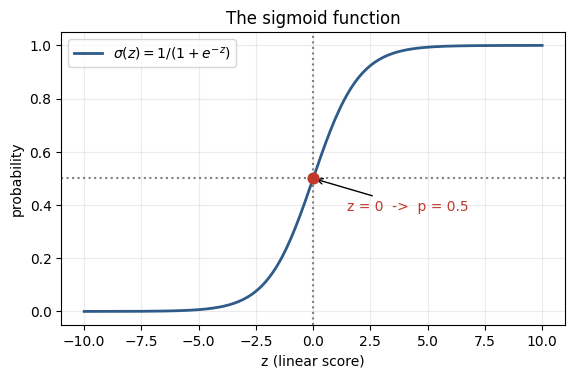

sigma(0) = 0.5 | sigma(-10) = 4.5e-05 | sigma(10) = 0.999955


In [2]:
z = np.linspace(-10, 10, 200)            # (a) 200 values of z between -10 and 10
sig = sigmoid(z)                          # (b) sigma(z) = 1 / (1 + e^-z)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(z, sig, color=BLUE, lw=2, label=r"$\sigma(z)=1/(1+e^{-z})$")
ax.scatter([0], [sigmoid(0)], color=RED, zorder=5, s=60)                       # (c) mark z = 0
ax.annotate("z = 0  ->  p = 0.5", (0, 0.5), (1.5, 0.38), arrowprops=dict(arrowstyle="->"), color=RED)
ax.axhline(0.5, color="gray", ls=":"); ax.axvline(0, color="gray", ls=":")
ax.set_xlabel("z (linear score)"); ax.set_ylabel("probability"); ax.set_title("The sigmoid function"); ax.legend(); plt.show()
print("sigma(0) =", sigmoid(0), "| sigma(-10) =", round(sigmoid(-10), 6), "| sigma(10) =", round(sigmoid(10), 6))

**(c)** At z = 0 the sigmoid equals exactly **0.5**: a score of zero means the model is undecided between the two classes. Large positive scores give probabilities close to 1 and large negative scores give probabilities close to 0, and the output never leaves the interval (0, 1).

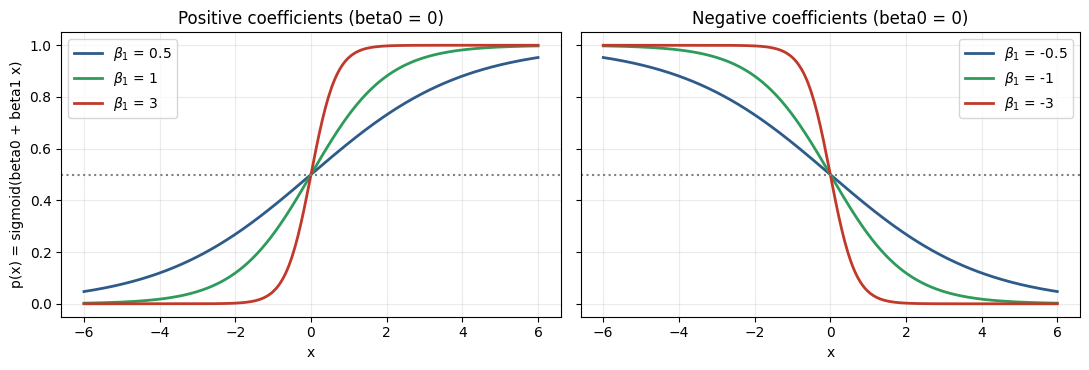

beta1 = 0.5: slope at the midpoint = beta1/4 = 0.125; p(x=1) = 0.622, p(x=-1) = 0.378
beta1 = 1: slope at the midpoint = beta1/4 = 0.250; p(x=1) = 0.731, p(x=-1) = 0.269
beta1 = 3: slope at the midpoint = beta1/4 = 0.750; p(x=1) = 0.953, p(x=-1) = 0.047


In [3]:
x = np.linspace(-6, 6, 300)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for b1, c in zip([0.5, 1, 3], [BLUE, GREEN, RED]):                  # (d) three positive values, beta0 = 0
    ax[0].plot(x, sigmoid(0 + b1 * x), color=c, lw=2, label=fr"$\beta_1$ = {b1}")
for b1, c in zip([-0.5, -1, -3], [BLUE, GREEN, RED]):               # (e) the same with negative coefficients
    ax[1].plot(x, sigmoid(0 + b1 * x), color=c, lw=2, label=fr"$\beta_1$ = {b1}")
for a, t in zip(ax, ["Positive coefficients (beta0 = 0)", "Negative coefficients (beta0 = 0)"]):
    a.axhline(0.5, color="gray", ls=":"); a.set_xlabel("x"); a.set_title(t); a.legend()
ax[0].set_ylabel("p(x) = sigmoid(beta0 + beta1 x)"); plt.tight_layout(); plt.show()
for b1 in [0.5, 1, 3]: print(f"beta1 = {b1}: slope at the midpoint = beta1/4 = {b1/4:.3f}; p(x=1) = {sigmoid(b1):.3f}, p(x=-1) = {sigmoid(-b1):.3f}")

**(f) Effect of the coefficient.**
* **Sign:** a positive β₁ gives a curve that rises with x (more x, higher probability of class 1); a negative β₁ gives the mirror image, falling with x.
* **Magnitude:** a larger |β₁| makes the S-curve steeper (the slope at the midpoint is β₁/4): the model moves quickly from "almost certainly 0" to "almost certainly 1" around x = 0. A small |β₁| gives a gentle curve, so the model stays uncertain over a wide range of x.
* With β₀ = 0 all curves cross p = 0.5 at x = 0. In general the 50% point is at x = −β₀/β₁, so β₀ only shifts the curve left or right.

## Task 2: Building a Classifier with One Input

In [4]:
rng = np.random.default_rng(42)
study_hours = rng.uniform(0, 10, 300)
true_probability = 1 / (1 + np.exp(-(-4 + 0.8 * study_hours)))
passed = rng.binomial(1, true_probability)
df = pd.DataFrame({"study_hours": study_hours, "passed": passed})
df.head()

,study_hours,passed
0,7.739560,1
1,4.388784,0
2,8.585979,1
3,6.973680,1
4,0.941773,0


In [5]:
# (a) shape, missing values, class counts
print("shape:", df.shape); print("missing values per column:\n", df.isna().sum()); print("class counts:\n", df["passed"].value_counts().sort_index())
print("pass rate:", round(df["passed"].mean(), 3))

shape: (300, 2)
missing values per column:
 study_hours    0
passed         0
dtype: int64
class counts:
 passed
0    161
1    139
Name: count, dtype: int64
pass rate: 0.463


In [6]:
# (b) stratified 80/20 split, random_state = 42
X_train, X_test, y_train, y_test = train_test_split(df[["study_hours"]], df["passed"], test_size=0.2, stratify=df["passed"], random_state=42)
print("train:", X_train.shape, "test:", X_test.shape, "| pass rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))
# (c) train the logistic regression model
model = LogisticRegression().fit(X_train, y_train)
# (d) learned intercept and coefficient
print("intercept:", round(model.intercept_[0], 4), "| coefficient:", round(model.coef_[0][0], 4), "  (values used to generate the data: -4 and 0.8)")
print("50% probability at study hours =", round(-model.intercept_[0] / model.coef_[0][0], 3), "(true value: 5.0)")

train: (240, 1) test: (60, 1) | pass rate train/test: 0.462 0.467
intercept: -4.5664 | coefficient: 0.8846   (values used to generate the data: -4 and 0.8)
50% probability at study hours = 5.162 (true value: 5.0)


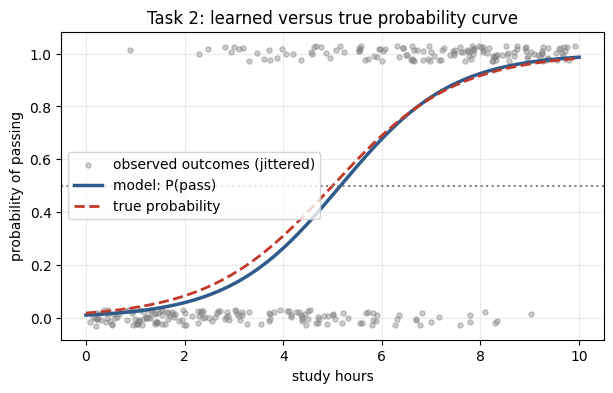

In [7]:
# (e) predicted probability of passing against study hours
grid = pd.DataFrame({"study_hours": np.linspace(0, 10, 200)})
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df["study_hours"], df["passed"] + np.random.default_rng(0).uniform(-0.03, 0.03, len(df)), s=14, alpha=0.4, color="gray", label="observed outcomes (jittered)")
ax.plot(grid["study_hours"], model.predict_proba(grid)[:, 1], color=BLUE, lw=2.5, label="model: P(pass)")
ax.plot(grid["study_hours"], sigmoid(-4 + 0.8 * grid["study_hours"]), color=RED, ls="--", lw=2, label="true probability")
ax.axhline(0.5, color="gray", ls=":"); ax.set_xlabel("study hours"); ax.set_ylabel("probability of passing"); ax.legend(); ax.set_title("Task 2: learned versus true probability curve"); plt.show()

In [8]:
# (f) predicted probabilities for 2, 5 and 8 hours
hrs = pd.DataFrame({"study_hours": [2, 5, 8]})
tab = pd.DataFrame({"study_hours": [2, 5, 8], "model P(pass)": model.predict_proba(hrs)[:, 1].round(4), "true P(pass)": sigmoid(-4 + 0.8 * hrs["study_hours"]).round(4)})
tab

,study_hours,model P(pass),true P(pass)
0,2,0.0575,0.0832
1,5,0.4642,0.5000
2,8,0.9249,0.9168


unpenalised fit over 200 repeats (n = 240 each): intercept mean -4.03 (sd 0.49), coefficient mean 0.81 (sd 0.09)
share of repeats with a coefficient at least as far from 0.8 as ours (0.885): 0.34


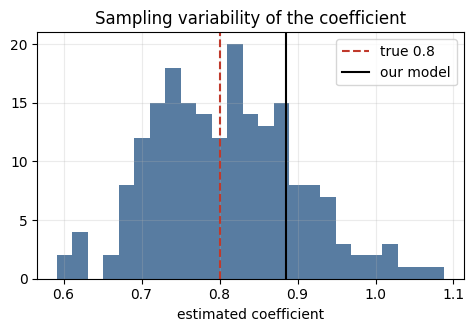

In [9]:
# (g) why do the learned coefficients differ from (-4, 0.8)?  Repeat the whole experiment with 200 different random seeds
est = []
for s in range(200):
    r = np.random.default_rng(1000 + s); h = r.uniform(0, 10, 240); yy = r.binomial(1, sigmoid(-4 + 0.8 * h))
    m = LogisticRegression(penalty=None).fit(h.reshape(-1, 1), yy); est.append((m.intercept_[0], m.coef_[0][0]))
est = np.array(est)
print(f"unpenalised fit over 200 repeats (n = 240 each): intercept mean {est[:,0].mean():.2f} (sd {est[:,0].std():.2f}), coefficient mean {est[:,1].mean():.2f} (sd {est[:,1].std():.2f})")
print(f"share of repeats with a coefficient at least as far from 0.8 as ours (0.885): {np.mean(np.abs(est[:,1]-0.8) >= abs(model.coef_[0][0]-0.8)):.2f}")
fig, ax = plt.subplots(figsize=(5.5, 3.2)); ax.hist(est[:, 1], bins=25, color=BLUE, alpha=0.8); ax.axvline(0.8, color=RED, ls="--", label="true 0.8"); ax.axvline(model.coef_[0][0], color="k", label="our model"); ax.legend(); ax.set_xlabel("estimated coefficient"); ax.set_title("Sampling variability of the coefficient"); plt.show()

**(g)** The learned values (intercept −4.57, coefficient 0.885) differ from the generating values (−4, 0.8) for three reasons:
1. **The labels are random.** Each student's outcome is a Bernoulli draw from the true probability, so the data contain only a noisy view of the curve: a student with true probability 0.5 may pass or fail. A finite sample of 240 training points cannot recover the parameters exactly. Repeating the experiment 200 times, the unpenalised coefficient averages 0.81 with a standard deviation of 0.09 (the intercept averages −4.03 with a standard deviation of 0.49; see the histogram above). Our value, 0.885, is within one standard deviation of 0.8, and about a third of the repeats were even farther away, so the difference is ordinary sampling variation, not a fault of the model.
2. **Finite sample and the particular split.** Only 240 of the 300 students are used for training, and which students land in the training set changes the estimate.
3. **Regularization.** scikit-learn's LogisticRegression applies a small L2 penalty by default (C = 1), which shrinks coefficients slightly; the effect here is much smaller than the sampling noise (an unpenalised fit gives 0.895 and −4.62).
The fitted model nevertheless places the 50% point at about 5.2 hours (true value 5.0), and the predicted probabilities at 2, 5 and 8 hours are close to the true ones.

## Task 3: Evaluating Predictions and Changing the Threshold

In [10]:
# (a) test-set probabilities: predict_proba returns [P(class 0), P(class 1)]; class 1 = column index 1
print("classes_ =", model.classes_, "-> class 1 is column", list(model.classes_).index(1))
proba = model.predict_proba(X_test)[:, 1]
print(proba[:6].round(3))

classes_ = [0 1] -> class 1 is column 1
[0.911 0.253 0.835 0.059 0.076 0.018]


In [11]:
# (b)-(e) predictions, metrics and confusion matrices for thresholds 0.3, 0.5 and 0.7 (passing = positive class)
rows, cms = [], {}
for t in [0.3, 0.5, 0.7]:
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel(); cms[t] = pd.DataFrame([[tn, fp], [fn, tp]], index=["actual 0 (fail)", "actual 1 (pass)"], columns=["predicted 0", "predicted 1"])
    rows.append({"threshold": t, "accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred), "TN": tn, "FP": fp, "FN": fn, "TP": tp})
results = pd.DataFrame(rows).round(3); results

,threshold,accuracy,precision,recall,F1,TN,FP,FN,TP
0,0.3,0.717,0.657,0.821,0.730,20,12,5,23
1,0.5,0.783,0.759,0.786,0.772,25,7,6,22
2,0.7,0.750,0.741,0.714,0.727,25,7,8,20


In [12]:
for t, cm in cms.items():
    print(f"Confusion matrix, threshold {t}"); display(cm); print()

Confusion matrix, threshold 0.3


,predicted 0,predicted 1
actual 0 (fail),20,12
actual 1 (pass),5,23



Confusion matrix, threshold 0.5


,predicted 0,predicted 1
actual 0 (fail),25,7
actual 1 (pass),6,22



Confusion matrix, threshold 0.7


,predicted 0,predicted 1
actual 0 (fail),25,7
actual 1 (pass),8,20


**(f) Effect of the threshold.** Lowering the threshold labels more students as "pass": predicted positives rise, so **false negatives fall** (fewer real passers are missed) but **false positives rise** (more students who failed are predicted to pass). From 0.7 down to 0.3 the false negatives fall from 8 to 5 and recall rises from 0.71 to 0.82, while false positives rise from 7 to 12 and precision falls from 0.74 to 0.66. Raising the threshold does the opposite. Accuracy is highest at 0.5 (0.78), where the two kinds of error are roughly balanced for this nearly balanced data set; no threshold is "correct" in general, the choice depends on the cost of each error.

**(g) Which event should be the positive class for identifying students who may need academic support?** The students who are **not going to pass** (failing, class 0) should be the positive class, because they are the ones we want to find. Recall then means "of all students who really will struggle, what fraction did we flag?", the quantity a support programme cares about: a missed struggling student (false negative) goes without help. If instead "pass" is the positive class, recall measures how many passers we find, which says nothing about the students who need support. The code below makes the switch (predicted probability of failing = 1 − P(pass)). In the results, no failing student has a P(fail) between 0.3 and 0.5, so recall is the same at both thresholds (25 of the 32 failing test students found, 0.781) and only precision changes (0.758 at 0.3, 0.806 at 0.5); at 0.7 recall drops to 0.625 (20 of 32), which means 12 students who needed support would be missed.

In [13]:
p_fail = 1 - proba; y_fail = 1 - y_test.values
rows = []
for t in [0.3, 0.5, 0.7]:
    pred = (p_fail >= t).astype(int); tn, fp, fn, tp = confusion_matrix(y_fail, pred).ravel()
    rows.append({"threshold on P(fail)": t, "students flagged": int(pred.sum()), "recall (fails found)": recall_score(y_fail, pred), "precision": precision_score(y_fail, pred), "missed (FN)": fn, "wrongly flagged (FP)": fp})
pd.DataFrame(rows).round(3)

,threshold on P(fail),students flagged,recall (fails found),precision,missed (FN),wrongly flagged (FP)
0,0.3,33,0.781,0.758,7,8
1,0.5,31,0.781,0.806,7,6
2,0.7,25,0.625,0.800,12,5


## Task 4: Extending the Model to Multiple Inputs

In [14]:
rng = np.random.default_rng(21); n = 500
study_hours = rng.uniform(0, 10, n); attendance_pct = rng.uniform(40, 100, n)
z = -8 + 0.7 * study_hours + 0.06 * attendance_pct
true_probability = 1 / (1 + np.exp(-z)); passed = rng.binomial(1, true_probability)
df_multi = pd.DataFrame({"study_hours": study_hours, "attendance_pct": attendance_pct, "passed": passed})
print(df_multi["passed"].value_counts().sort_index().to_dict(), "| shape", df_multi.shape)

# (a) ONE stratified split used by both models
Xm = df_multi[["study_hours", "attendance_pct"]]; ym = df_multi["passed"]
Xm_train, Xm_test, ym_train, ym_test = train_test_split(Xm, ym, test_size=0.2, stratify=ym, random_state=42)
# (b) Model A: study hours only      (c) Model B: study hours and attendance
model_A = LogisticRegression().fit(Xm_train[["study_hours"]], ym_train)
model_B = LogisticRegression().fit(Xm_train, ym_train)

{0: 276, 1: 224} | shape (500, 3)


,accuracy,precision,recall,F1,ROC-AUC
Model A (hours),0.80,0.778,0.778,0.778,0.894
Model B (hours + attendance),0.84,0.837,0.800,0.818,0.925


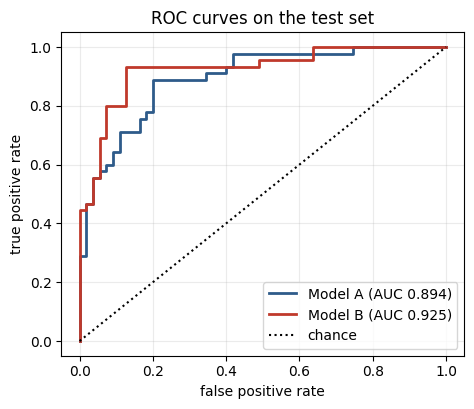

In [15]:
# (d) comparison on the same test set (threshold 0.5 for class metrics; probabilities for ROC-AUC)
def evaluate(m, X):
    p = m.predict_proba(X)[:, 1]; c = (p >= 0.5).astype(int)
    return {"accuracy": accuracy_score(ym_test, c), "precision": precision_score(ym_test, c), "recall": recall_score(ym_test, c), "F1": f1_score(ym_test, c), "ROC-AUC": roc_auc_score(ym_test, p)}
comp = pd.DataFrame({"Model A (hours)": evaluate(model_A, Xm_test[["study_hours"]]), "Model B (hours + attendance)": evaluate(model_B, Xm_test)}).T.round(3); display(comp)
fig, ax = plt.subplots(figsize=(5.2, 4.2))
for name, m, X, c in [("Model A", model_A, Xm_test[["study_hours"]], BLUE), ("Model B", model_B, Xm_test, RED)]:
    fpr, tpr, _ = roc_curve(ym_test, m.predict_proba(X)[:, 1]); ax.plot(fpr, tpr, color=c, lw=2, label=f"{name} (AUC {roc_auc_score(ym_test, m.predict_proba(X)[:,1]):.3f})")
ax.plot([0, 1], [0, 1], "k:", label="chance"); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.legend(); ax.set_title("ROC curves on the test set"); plt.show()

In [16]:
# (e) coefficients of Model B
print("Model B intercept:", model_B.intercept_.round(3), "| coefficients [study_hours, attendance_pct]:", model_B.coef_[0].round(4), "  (generating values: -8, 0.7, 0.06)")
print("odds multiplier per extra study hour:", round(np.exp(model_B.coef_[0][0]), 2), "| per extra attendance point:", round(np.exp(model_B.coef_[0][1]), 3), "| per extra 10 attendance points:", round(np.exp(10 * model_B.coef_[0][1]), 2))

Model B intercept: [-7.448] | coefficients [study_hours, attendance_pct]: [0.6839 0.0519]   (generating values: -8, 0.7, 0.06)
odds multiplier per extra study hour: 1.98 | per extra attendance point: 1.053 | per extra 10 attendance points: 1.68


**(e) Interpretation of Model B's coefficients.** Both coefficients are **positive** (study hours 0.68, attendance 0.052), so with the other input fixed, more study hours and higher attendance both raise the log-odds, and hence the probability, of passing. Per extra study hour the odds of passing are multiplied by e^0.684 = 1.98 (about double); per extra attendance percentage point by e^0.052 = 1.05, or 1.68 per 10 points. The raw coefficients are not directly comparable because the two inputs have different units (hours versus percentage points); see Task 5(d). The fitted values are close to those used to generate the data (0.7 and 0.06).

In [17]:
# (f) two students with similar study hours and different attendance
students = pd.DataFrame({"study_hours": [5.0, 5.0], "attendance_pct": [50, 90]}, index=["student 1 (50% attendance)", "student 2 (90% attendance)"])
students["P(pass), Model A"] = model_A.predict_proba(students[["study_hours"]])[:, 1].round(3)
students["P(pass), Model B"] = model_B.predict_proba(students[["study_hours", "attendance_pct"]])[:, 1].round(3)
display(students); print("odds ratio of student 2 versus student 1 (Model B):", round(np.exp(40 * model_B.coef_[0][1]), 2))

,study_hours,attendance_pct,"P(pass), Model A","P(pass), Model B"
student 1 (50% attendance),5.0,50,0.42,0.193
student 2 (90% attendance),5.0,90,0.42,0.656


odds ratio of student 2 versus student 1 (Model B): 7.98


**(f)** With the same 5 study hours, Model A cannot tell the students apart (it ignores attendance and gives both the same probability, about 0.4), whereas Model B gives the student with 50% attendance a **19%** chance of passing and the student with 90% attendance a **66%** chance. Attendance raises the odds of passing by e^(40 × 0.052) ≈ 8.0 times.

In [18]:
# (g) does adding an input ALWAYS help?  Add a column of pure noise and compare over 30 random splits
rows = []
for seed in range(30):
    noise = np.random.default_rng(1000 + seed).normal(size=n); X3 = Xm.assign(noise=noise)
    a, b, ya, yb = train_test_split(X3, ym, test_size=0.2, stratify=ym, random_state=seed)
    mB = LogisticRegression().fit(a[["study_hours", "attendance_pct"]], ya); mN = LogisticRegression().fit(a, ya)
    mA = LogisticRegression().fit(a[["study_hours"]], ya)
    rows.append({"AUC A": roc_auc_score(yb, mA.predict_proba(b[["study_hours"]])[:, 1]), "AUC B": roc_auc_score(yb, mB.predict_proba(b[["study_hours", "attendance_pct"]])[:, 1]), "AUC B + noise": roc_auc_score(yb, mN.predict_proba(b)[:, 1])})
r = pd.DataFrame(rows); print(r.mean().round(4).to_dict())
print("share of splits where B beats A:", round((r["AUC B"] > r["AUC A"]).mean(), 2), "| share where B + noise beats B:", round((r["AUC B + noise"] > r["AUC B"]).mean(), 2))

{'AUC A': 0.865, 'AUC B': 0.8951, 'AUC B + noise': 0.8943}
share of splits where B beats A: 1.0 | share where B + noise beats B: 0.47


**(g) Does adding an input always improve performance on unseen data? No.** Adding attendance helped: on the test split Model B improved accuracy from 0.80 to 0.84 and ROC-AUC from 0.894 to 0.925, and Model B had the higher AUC in all 30 of 30 repeated splits (mean AUC 0.895 against 0.865 for Model A), because attendance genuinely influences the outcome. But the improvement comes from the *information* in the input, not from the mere fact that there is one more: when I added a column of pure random noise, the mean test AUC did not improve (about 0.894 versus 0.895 without it) and the noisy model won in only about half of the splits. A useless input adds a coefficient that must be estimated from limited data, which can slightly hurt generalization (more variance), and on the training set it can only help; so performance must always be judged on held-out data.

## Task 5: Investigating Data Leakage

In [19]:
# (a) Workflow B as a Pipeline: split first, the scaler is fitted on TRAINING data only
pipe = make_pipeline(StandardScaler(), LogisticRegression())
pipe.fit(Xm_train, ym_train)                      # fit_transform on train, then the classifier
pB = pipe.predict_proba(Xm_test)[:, 1]            # the same scaler (train statistics) transforms the test set
print("Workflow B: test accuracy", round(accuracy_score(ym_test, (pB >= 0.5).astype(int)), 4), "| ROC-AUC", round(roc_auc_score(ym_test, pB), 4))

# Workflow A (leaky): standardize the FULL data set first, then split
Xs = StandardScaler().fit_transform(Xm)
a, b, ya, yb = train_test_split(Xs, ym, test_size=0.2, stratify=ym, random_state=42)
leaky = LogisticRegression().fit(a, ya); pA = leaky.predict_proba(b)[:, 1]
print("Workflow A: test accuracy", round(accuracy_score(yb, (pA >= 0.5).astype(int)), 4), "| ROC-AUC", round(roc_auc_score(yb, pA), 4))
sc = pipe[0]
print("\nmean used for scaling  - Workflow B (train only):", sc.mean_.round(3), "| Workflow A (all rows, includes test):", Xm.mean().values.round(3))
print("std  used for scaling  - Workflow B (train only):", sc.scale_.round(3), "| Workflow A (all rows, includes test):", Xm.std(ddof=0).values.round(3))
print("mean of the test rows themselves:", Xm_test.mean().values.round(3))

Workflow B: test accuracy 0.85 | ROC-AUC 0.9253
Workflow A: test accuracy 0.85 | ROC-AUC 0.9253

mean used for scaling  - Workflow B (train only): [ 4.959 70.88 ] | Workflow A (all rows, includes test): [ 4.954 70.576]
std  used for scaling  - Workflow B (train only): [ 2.897 16.967] | Workflow A (all rows, includes test): [ 2.873 17.147]
mean of the test rows themselves: [ 4.933 69.362]


**(b) What leaks in Workflow A.** The mean and standard deviation used to standardize the data are computed from **all** rows, including the rows that later become the test set. The training features are therefore transformed with statistics that contain information about the test observations (above, the training mean of study hours is 4.959 whereas the all-rows mean, which includes the test rows, is 4.954). The model is then evaluated on data whose summary statistics helped build the pipeline, so the test set is no longer completely unseen.

**(c) Why a small difference in scores does not make Workflow A valid.** Here the test scores of the two workflows are identical (accuracy 0.85, ROC-AUC 0.925) because standardization is a mild transformation and the leak is small. But a method is valid because of how it is designed, not because the damage happened to be small on one data set: the leak can be large with small data sets, outliers, many features, or procedures that use more of the data (feature selection, imputation, PCA, target encoding), and the size cannot be known beforehand. Workflow B costs nothing extra and removes the question, so it should always be used (and in cross-validation the scaler must be refitted inside every fold, which a Pipeline does automatically).

In [20]:
# (d) coefficients per original unit versus per standardized unit
orig = pd.Series(model_B.coef_[0], index=["study_hours", "attendance_pct"])                 # per original unit (Model B above)
std = pd.Series(pipe[-1].coef_[0], index=["study_hours", "attendance_pct"])                  # per standard deviation
tab = pd.DataFrame({"per original unit": orig, "std of the input": sc.scale_, "per standardized unit (SD)": std, "odds x per original unit": np.exp(orig), "odds x per +1 SD": np.exp(std)}).round(3); tab

,per original unit,std of the input,per standardized unit (SD),odds x per original unit,odds x per +1 SD
study_hours,0.684,2.897,1.912,1.982,6.764
attendance_pct,0.052,16.967,0.843,1.053,2.324


**(d) Per-unit and per-standardized-unit coefficients cannot be compared directly.** A coefficient is "change in log-odds per **one unit of that input**", and the unit differs between inputs. Per original unit, study hours (0.68, one hour) looks more than 13 times as influential as attendance (0.052, one percentage point), but one hour is a large move (the standard deviation of study hours is 2.9 hours) while one percentage point is a tiny one (the standard deviation of attendance is 17 points). After standardizing, each coefficient measures the change in log-odds for a **one-standard-deviation** change: study hours 1.91 and attendance 0.84, so a typical difference in study hours is about 2.3 times as influential as a typical difference in attendance, and the odds are multiplied by 6.8 and 2.3 per standard deviation, respectively. Standardized coefficients make inputs comparable in typical-change terms (not in importance for decisions in the real world), whereas per-unit coefficients are easier to explain ("each extra hour doubles the odds"). A coefficient also changes meaning with the units chosen: measuring study time in minutes would divide it by 60.

## Task 6: Research Aspect: Investigate and Reflect

**(a) What does logistic regression learn during training?** It learns the weights β₀, β₁, … of a linear score z = β₀ + β₁x₁ + … such that the sigmoid of the score is as close as possible to the observed outcomes. Training chooses the weights that minimize the cross-entropy (log) loss, equivalently maximize the likelihood of the observed labels. In Task 2 it learned that the log-odds of passing rise by about 0.88 per study hour, with the 50% point at about 5.2 hours. It does not store the training examples; everything it knows is in the coefficients.

**(b) Probability prediction versus class prediction.** The probability (predict_proba) is the model's graded estimate, for example "P(pass) = 0.66"; the class (predict) is a hard yes/no obtained by comparing the probability with a threshold (0.5 by default). The probability carries more information (the student at 0.51 and the student at 0.99 get the same class), supports ranking and cost-based decisions, and can be checked for calibration; the class is what a final action needs.

**(c) Effect of the threshold on errors.** A lower threshold gives more positive predictions: fewer false negatives (recall up) but more false positives (precision down). A higher threshold does the opposite. In Task 3 moving from 0.7 to 0.3 cut missed passers from 8 to 5 and raised false alarms from 7 to 12. The threshold should be chosen from the cost of each error, using validation data.

**(d) Why evaluate on data not used for training?** Training performance measures how well the model fits data it has already seen, and it is optimistic; only data that took no part in fitting, scaling or tuning show how well the model generalizes to new students. Leakage (Task 5) silently breaks this separation.

**(e) A limitation and an experiment.** The model assumes the log-odds are a straight line in the inputs, so it cannot represent effects such as diminishing returns of study hours, or an interaction in which attendance matters more for students who study little. *Experiment:* add a squared study-hours term and an hours × attendance interaction, compare test ROC-AUC and the log loss with the plain model over repeated stratified splits, and inspect calibration plots and residual patterns; if the richer model does not clearly beat the simple one on held-out data, the straight-line assumption is adequate. (A second limitation: the synthetic data come from a straight-line log-odds, so real data may behave differently.)

## Final Conclusion

Logistic regression turns a linear score into a probability through the sigmoid, so its coefficients are changes in log-odds and e^β is an odds multiplier. On the synthetic study-hours data it recovered the generating relationship reasonably well: the coefficient was 0.88 against a true 0.8, and the 50% point was about 5.2 hours. Differences from the true values came mainly from the random outcomes and the finite sample. Probabilities become decisions only through a threshold: lowering it from 0.7 to 0.3 raised recall from 0.71 to 0.82 but also raised false alarms, so the threshold should reflect the cost of each error and the positive class should be the event we want to find. Adding attendance improved the test ROC-AUC from 0.894 to 0.925, whereas a random noise input did not help, so inputs must carry information and be judged on held-out data. Scaling must be fitted on the training data only: a Pipeline prevents leakage, and standardized coefficients compare inputs in typical-change terms. Finally, the model is limited by its straight-line log-odds, which should be tested with richer features such as squared and interaction terms, always judged on held-out data. A limitation of this study is that the data are synthetic, so real data may be noisier.